In [1]:
import pandas as pd


In [2]:
df = pd.read_csv("cardio_train.csv", sep=";")
df.head()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


In [3]:
df.shape

(70000, 13)

In [4]:
df.columns

Index(['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo',
       'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio'],
      dtype='str')

In [5]:
df.isnull().sum()


id             0
age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco           0
active         0
cardio         0
dtype: int64

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


In [7]:
df.describe()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
count,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000
mean,49972.419900,19468.865814,1.349571,164.359229,74.205690,128.817286,96.630414,1.366871,1.226457,0.088129,0.053771,0.803729,0.499700
std,28851.302323,2467.251667,0.476838,8.210126,14.395757,154.011419,188.472530,0.680250,0.572270,0.283484,0.225568,0.397179,0.500003
min,0.000000,10798.000000,1.000000,55.000000,10.000000,-150.000000,-70.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,25006.750000,17664.000000,1.000000,159.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
50%,50001.500000,19703.000000,1.000000,165.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
75%,74889.250000,21327.000000,2.000000,170.000000,82.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000
max,99999.000000,23713.000000,2.000000,250.000000,200.000000,16020.000000,11000.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df["cardio"].value_counts()

cardio
0    35021
1    34979
Name: count, dtype: int64

In [10]:
df["cardio"].value_counts(normalize=True) * 100

cardio
0    50.03
1    49.97
Name: proportion, dtype: float64

In [11]:
df["ap_hi"].describe()

count    70000.000000
mean       128.817286
std        154.011419
min       -150.000000
25%        120.000000
50%        120.000000
75%        140.000000
max      16020.000000
Name: ap_hi, dtype: float64

In [12]:
df["ap_lo"].describe()

count    70000.000000
mean        96.630414
std        188.472530
min        -70.000000
25%         80.000000
50%         80.000000
75%         90.000000
max      11000.000000
Name: ap_lo, dtype: float64

In [13]:
print("Negative ap_hi:", (df["ap_hi"] < 0).sum())
print("Negative ap_lo:", (df["ap_lo"] < 0).sum())

Negative ap_hi: 7
Negative ap_lo: 1


In [14]:
print("Very high ap_hi:", (df["ap_hi"] > 250).sum())
print("Very high ap_lo:", (df["ap_lo"] > 150).sum())

Very high ap_hi: 40
Very high ap_lo: 975


In [15]:
print("Minimum age in days:", df["age"].min())
print("Maximum age in days:", df["age"].max())

Minimum age in days: 10798
Maximum age in days: 23713


In [16]:
df[(df["ap_hi"] < 0) | (df["ap_lo"] < 0)]

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
4607,6525,15281,1,165,78.0,-100,80,2,1,0,0,1,0
16021,22881,22108,2,161,90.0,-115,70,1,1,0,0,1,0
20536,29313,15581,1,153,54.0,-100,70,1,1,0,0,1,0
23988,34295,18301,1,162,74.0,-140,90,1,1,0,0,1,1
25240,36025,14711,2,168,50.0,-120,80,2,1,0,0,0,1
35040,50055,23325,2,168,59.0,-150,80,1,1,0,0,1,1
46627,66571,23646,2,160,59.0,-120,80,1,1,0,0,0,0
60106,85816,22571,1,167,74.0,15,-70,1,1,0,0,1,1


In [17]:
df[(df["ap_hi"] > 250) | (df["ap_lo"] > 150)]

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
228,314,17489,2,183,98.0,160,1100,1,2,1,0,1,1
241,334,21932,2,157,60.0,160,1000,2,1,0,0,0,1
260,357,18217,1,150,83.0,140,800,1,1,0,0,1,1
329,458,23407,1,176,63.0,160,1000,2,2,0,0,0,1
345,482,18704,1,154,81.0,140,1000,2,1,0,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
69771,99659,23330,1,167,81.0,160,1000,1,1,0,0,1,1
69872,99798,21808,1,152,56.0,160,1000,1,1,0,0,1,1
69878,99807,21239,2,168,95.0,160,1000,1,1,0,0,1,1
69885,99816,22417,2,166,78.0,170,1000,1,1,0,0,0,0


In [18]:
(df["ap_hi"] < df["ap_lo"]).sum()


np.int64(1234)

In [19]:
df_clean = df.copy()

In [20]:
df_clean = df_clean[
    (df_clean["ap_hi"] >= 60) &
    (df_clean["ap_hi"] <= 250) &
    (df_clean["ap_lo"] >= 40) &
    (df_clean["ap_lo"] <= 200) &
    (df_clean["ap_hi"] >= df_clean["ap_lo"])
]

In [21]:
df_clean.shape

(68674, 13)

In [22]:
df_clean[["ap_hi", "ap_lo"]].describe()

,ap_hi,ap_lo
count,68674.000000,68674.000000
mean,126.673355,81.307919
std,16.695237,9.455209
min,60.000000,40.000000
25%,120.000000,80.000000
50%,120.000000,80.000000
75%,140.000000,90.000000
max,240.000000,182.000000


In [23]:
df_clean["age_years"] = (df_clean["age"] / 365.25).astype(int)

In [24]:
df_clean["age_years"].describe()

count    68674.000000
mean        52.791682
std          6.765059
min         29.000000
25%         48.000000
50%         53.000000
75%         58.000000
max         64.000000
Name: age_years, dtype: float64

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

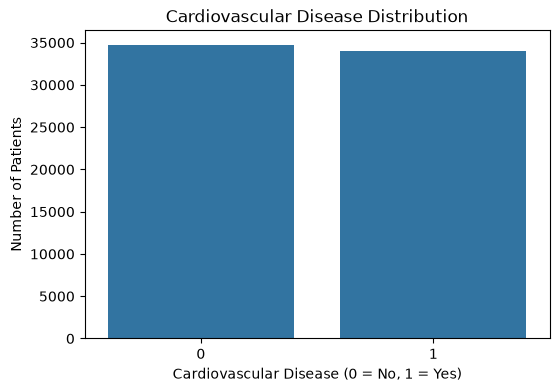

In [26]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df_clean, x="cardio")

plt.title("Cardiovascular Disease Distribution")
plt.xlabel("Cardiovascular Disease (0 = No, 1 = Yes)")
plt.ylabel("Number of Patients")

plt.show()

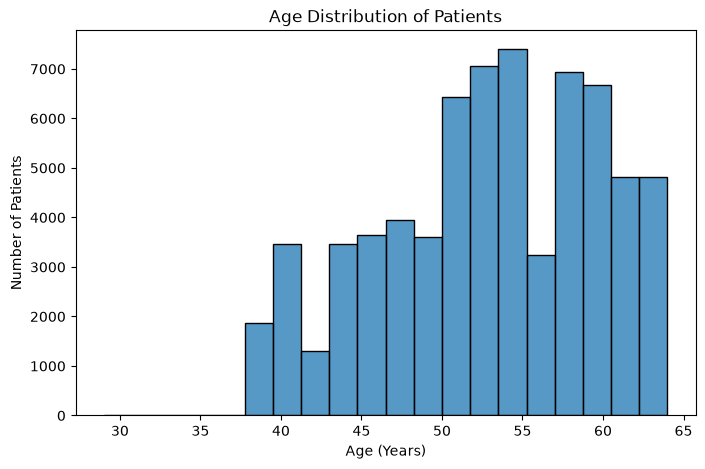

In [27]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df_clean, x="age_years", bins=20)

plt.title("Age Distribution of Patients")
plt.xlabel("Age (Years)")
plt.ylabel("Number of Patients")

plt.show()

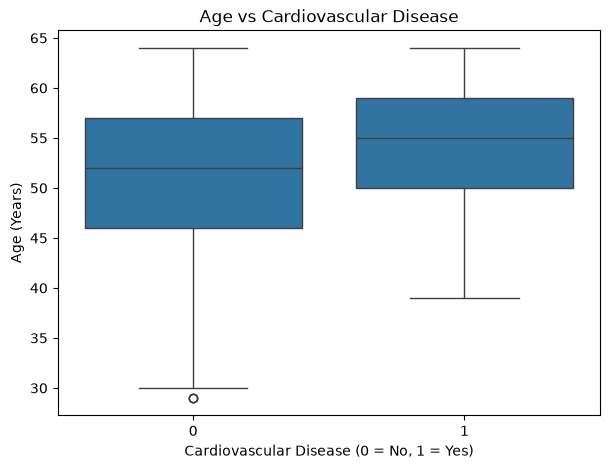

In [28]:
plt.figure(figsize=(7, 5))

sns.boxplot(data=df_clean, x="cardio", y="age_years")

plt.title("Age vs Cardiovascular Disease")
plt.xlabel("Cardiovascular Disease (0 = No, 1 = Yes)")
plt.ylabel("Age (Years)")

plt.show()

In [29]:
df_clean.groupby("cardio")["age_years"].mean()

cardio
0    51.190980
1    54.426591
Name: age_years, dtype: float64

In [30]:
df_clean.groupby("cardio")["age_years"].median()

cardio
0    52.0
1    55.0
Name: age_years, dtype: float64

In [31]:
df_clean["gender"].value_counts()

gender
1    44732
2    23942
Name: count, dtype: int64

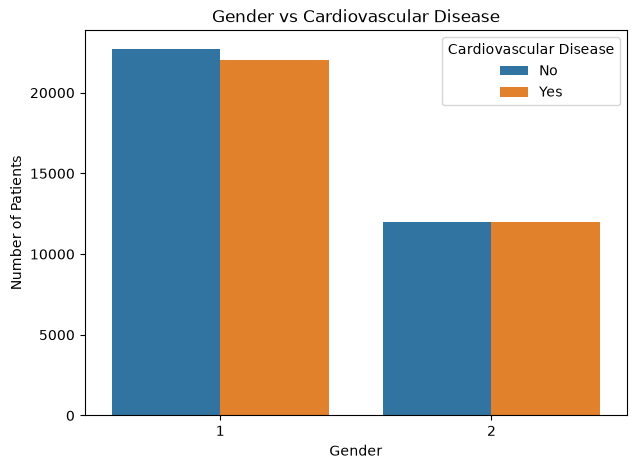

In [32]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df_clean, x="gender", hue="cardio")

plt.title("Gender vs Cardiovascular Disease")
plt.xlabel("Gender")
plt.ylabel("Number of Patients")
plt.legend(title="Cardiovascular Disease", labels=["No", "Yes"])

plt.show()

In [33]:
gender_cardio_pct = pd.crosstab(
    df_clean["gender"],
    df_clean["cardio"],
    normalize="index"
) * 100

gender_cardio_pct

cardio,0,1
gender,,
1,50.789144,49.210856
2,50.041768,49.958232


In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

In [35]:
import pandas as pd
import numpy as np

df = pd.read_csv("cardio_train.csv", sep=";")

In [36]:
df_clean = df.copy()

df_clean = df_clean[
    (df_clean["ap_hi"] >= 60) &
    (df_clean["ap_hi"] <= 250) &
    (df_clean["ap_lo"] >= 40) &
    (df_clean["ap_lo"] <= 200) &
    (df_clean["ap_hi"] >= df_clean["ap_lo"])
]

In [37]:
df_clean["age_years"] = (df_clean["age"] / 365.25).astype(int)

In [38]:
df_clean.shape

(68674, 14)

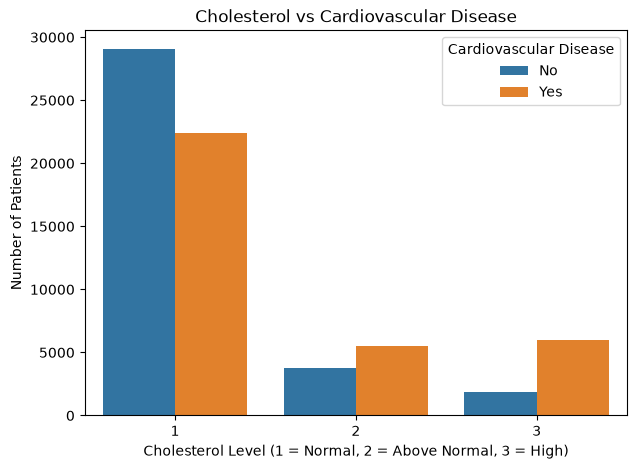

In [39]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df_clean, x="cholesterol", hue="cardio")

plt.title("Cholesterol vs Cardiovascular Disease")
plt.xlabel("Cholesterol Level (1 = Normal, 2 = Above Normal, 3 = High)")
plt.ylabel("Number of Patients")
plt.legend(title="Cardiovascular Disease", labels=["No", "Yes"])

plt.show()

In [40]:
chol_cardio_pct = pd.crosstab(
    df_clean["cholesterol"],
    df_clean["cardio"],
    normalize="index"
) * 100

chol_cardio_pct

cardio,0,1
cholesterol,,
1,56.458002,43.541998
2,40.356912,59.643088
3,23.748412,76.251588


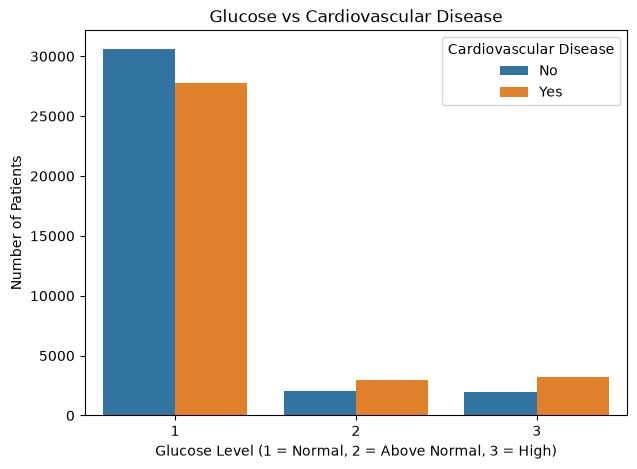

In [41]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df_clean, x="gluc", hue="cardio")

plt.title("Glucose vs Cardiovascular Disease")
plt.xlabel("Glucose Level (1 = Normal, 2 = Above Normal, 3 = High)")
plt.ylabel("Number of Patients")
plt.legend(title="Cardiovascular Disease", labels=["No", "Yes"])

plt.show()

In [42]:
gluc_cardio_pct = pd.crosstab(
    df_clean["gluc"],
    df_clean["cardio"],
    normalize="index"
) * 100

gluc_cardio_pct

cardio,0,1
gluc,,
1,52.442199,47.557801
2,41.128873,58.871127
3,38.240368,61.759632


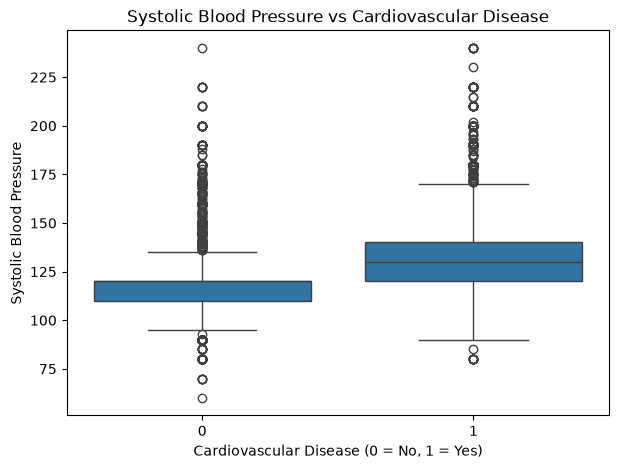

In [43]:
plt.figure(figsize=(7, 5))

sns.boxplot(data=df_clean, x="cardio", y="ap_hi")

plt.title("Systolic Blood Pressure vs Cardiovascular Disease")
plt.xlabel("Cardiovascular Disease (0 = No, 1 = Yes)")
plt.ylabel("Systolic Blood Pressure")

plt.show()

In [44]:
df_clean.groupby("cardio")["ap_hi"].agg(["mean", "median"])

,mean,median
cardio,,
0,119.603458,120.0
1,133.894331,130.0


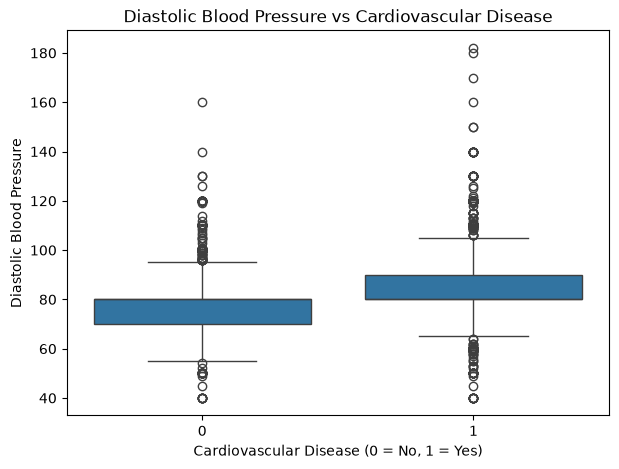

In [45]:
plt.figure(figsize=(7, 5))

sns.boxplot(data=df_clean, x="cardio", y="ap_lo")

plt.title("Diastolic Blood Pressure vs Cardiovascular Disease")
plt.xlabel("Cardiovascular Disease (0 = No, 1 = Yes)")
plt.ylabel("Diastolic Blood Pressure")

plt.show()

In [46]:
df_clean.groupby("cardio")["ap_lo"].agg(["mean", "median"])

,mean,median
cardio,,
0,78.125850,80.0
1,84.557986,80.0


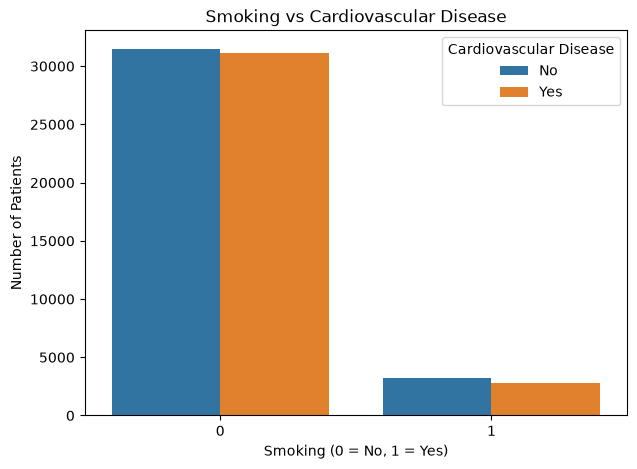

In [47]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df_clean, x="smoke", hue="cardio")

plt.title("Smoking vs Cardiovascular Disease")
plt.xlabel("Smoking (0 = No, 1 = Yes)")
plt.ylabel("Number of Patients")
plt.legend(title="Cardiovascular Disease", labels=["No", "Yes"])

plt.show()

In [48]:
smoke_cardio_pct = pd.crosstab(
    df_clean["smoke"],
    df_clean["cardio"],
    normalize="index"
) * 100

smoke_cardio_pct

cardio,0,1
smoke,,
0,50.275414,49.724586
1,53.153451,46.846549


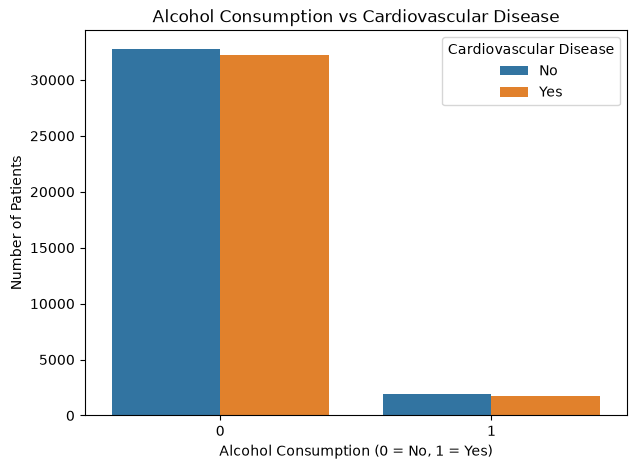

In [49]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df_clean, x="alco", hue="cardio")

plt.title("Alcohol Consumption vs Cardiovascular Disease")
plt.xlabel("Alcohol Consumption (0 = No, 1 = Yes)")
plt.ylabel("Number of Patients")
plt.legend(title="Cardiovascular Disease", labels=["No", "Yes"])

plt.show()

In [50]:
alco_cardio_pct = pd.crosstab(
    df_clean["alco"],
    df_clean["cardio"],
    normalize="index"
) * 100

alco_cardio_pct

cardio,0,1
alco,,
0,50.424550,49.575450
1,52.374454,47.625546


In [51]:
df_clean.columns

Index(['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo',
       'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio',
       'age_years'],
      dtype='str')

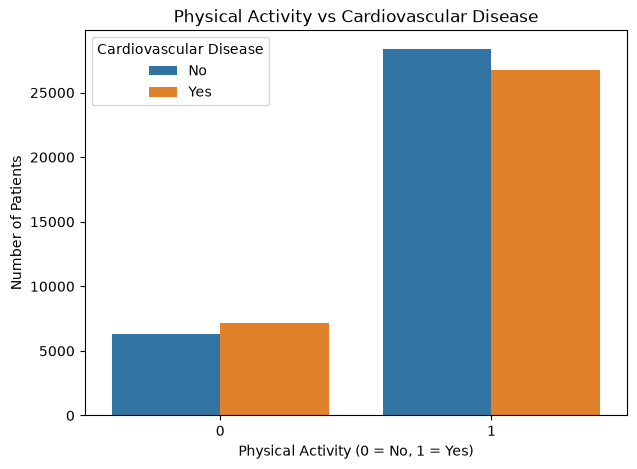

In [52]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df_clean, x="active", hue="cardio")

plt.title("Physical Activity vs Cardiovascular Disease")
plt.xlabel("Physical Activity (0 = No, 1 = Yes)")
plt.ylabel("Number of Patients")
plt.legend(title="Cardiovascular Disease", labels=["No", "Yes"])

plt.show()

In [53]:
active_cardio_pct = pd.crosstab(
    df_clean["active"],
    df_clean["cardio"],
    normalize="index"
) * 100

active_cardio_pct

cardio,0,1
active,,
0,46.745650,53.254350
1,51.454621,48.545379


In [54]:
df_clean.columns

Index(['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo',
       'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio',
       'age_years'],
      dtype='str')

In [55]:
df_clean["bmi"] = df_clean["weight"] / ((df_clean["height"] / 100) ** 2)

df_clean[["height", "weight", "bmi"]].head()

,height,weight,bmi
0,168,62.0,21.967120
1,156,85.0,34.927679
2,165,64.0,23.507805
3,169,82.0,28.710479
4,156,56.0,23.011177


In [56]:
def bmi_category(bmi):
    if bmi < 18.5:
        return "Underweight"
    elif bmi < 25:
        return "Normal"
    elif bmi < 30:
        return "Overweight"
    else:
        return "Obese"

df_clean["bmi_category"] = df_clean["bmi"].apply(bmi_category)

df_clean["bmi_category"].value_counts()

bmi_category
Normal         25425
Overweight     24624
Obese          17982
Underweight      643
Name: count, dtype: int64

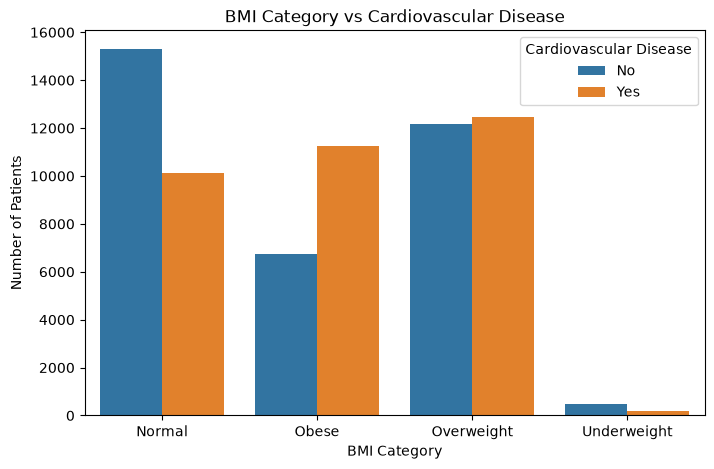

In [57]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df_clean, x="bmi_category", hue="cardio")

plt.title("BMI Category vs Cardiovascular Disease")
plt.xlabel("BMI Category")
plt.ylabel("Number of Patients")
plt.legend(title="Cardiovascular Disease", labels=["No", "Yes"])

plt.show()

In [58]:
bmi_cardio_pct = pd.crosstab(
    df_clean["bmi_category"],
    df_clean["cardio"],
    normalize="index"
) * 100

bmi_cardio_pct

cardio,0,1
bmi_category,,
Normal,60.212389,39.787611
Obese,37.531976,62.468024
Overweight,49.447693,50.552307
Underweight,72.472784,27.527216


In [59]:
df_clean["age_group"] = pd.cut(
    df_clean["age_years"],
    bins=[0, 35, 45, 55, 65, 100],
    labels=["Below 35", "35-45", "45-55", "55-65", "Above 65"],
    right=False
)

df_clean["age_group"].value_counts().sort_index()

age_group
Below 35        4
35-45       10099
45-55       27960
55-65       30611
Above 65        0
Name: count, dtype: int64

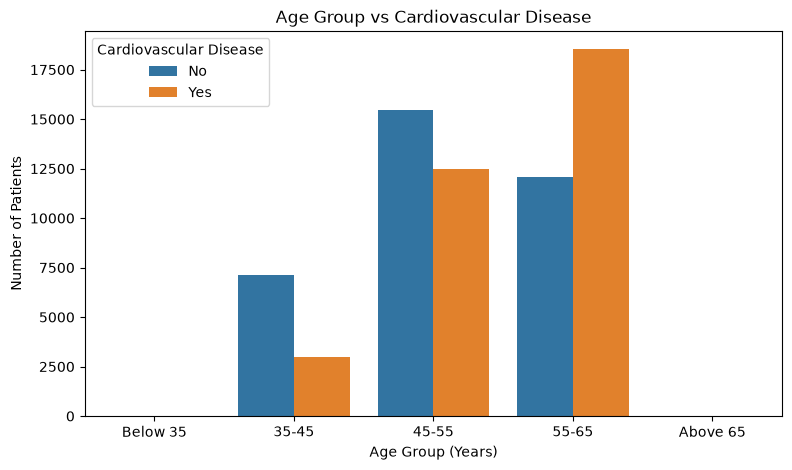

In [60]:
plt.figure(figsize=(9, 5))

sns.countplot(data=df_clean, x="age_group", hue="cardio")

plt.title("Age Group vs Cardiovascular Disease")
plt.xlabel("Age Group (Years)")
plt.ylabel("Number of Patients")
plt.legend(title="Cardiovascular Disease", labels=["No", "Yes"])

plt.show()

In [61]:
age_cardio_pct = pd.crosstab(
    df_clean["age_group"],
    df_clean["cardio"],
    normalize="index"
) * 100

age_cardio_pct

cardio,0,1
age_group,,
Below 35,100.000000,0.000000
35-45,70.709971,29.290029
45-55,55.321888,44.678112
55-65,39.485806,60.514194


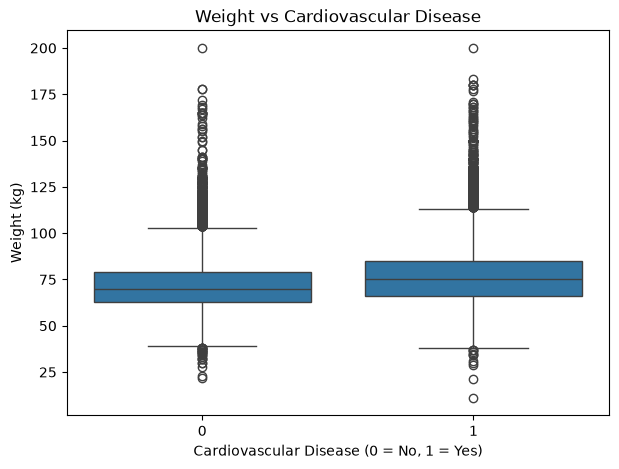

In [62]:
plt.figure(figsize=(7, 5))

sns.boxplot(data=df_clean, x="cardio", y="weight")

plt.title("Weight vs Cardiovascular Disease")
plt.xlabel("Cardiovascular Disease (0 = No, 1 = Yes)")
plt.ylabel("Weight (kg)")

plt.show()

In [63]:
df_clean.groupby("cardio")["weight"].agg(["mean", "median"])

,mean,median
cardio,,
0,71.570193,70.0
1,76.722753,75.0


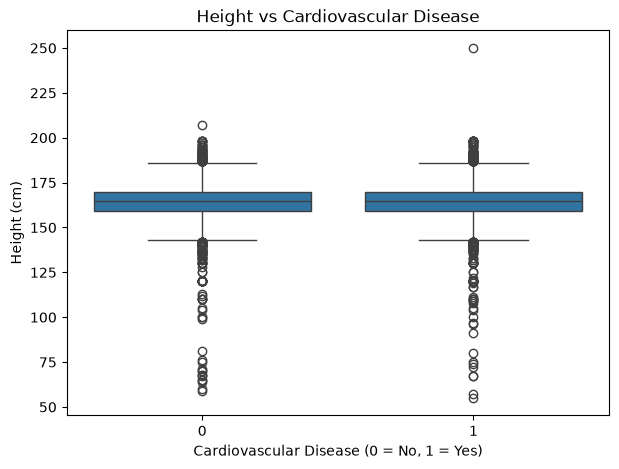

In [64]:
plt.figure(figsize=(7, 5))

sns.boxplot(data=df_clean, x="cardio", y="height")

plt.title("Height vs Cardiovascular Disease")
plt.xlabel("Cardiovascular Disease (0 = No, 1 = Yes)")
plt.ylabel("Height (cm)")

plt.show()

In [65]:
corr_cols = [
    "age_years",
    "height",
    "weight",
    "ap_hi",
    "ap_lo",
    "cholesterol",
    "gluc",
    "smoke",
    "alco",
    "active",
    "cardio"
]

corr_matrix = df_clean[corr_cols].corr()

corr_matrix

,age_years,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
age_years,1.000000,-0.081293,0.054581,0.209174,0.156360,0.154897,0.098613,-0.047538,-0.028817,-0.010047,0.239130
height,-0.081293,1.000000,0.291665,0.018683,0.036163,-0.050661,-0.018713,0.188278,0.094623,-0.007522,-0.010710
weight,0.054581,0.291665,1.000000,0.270925,0.253711,0.141124,0.107044,0.067021,0.067419,-0.017795,0.179738
ap_hi,0.209174,0.018683,0.270925,1.000000,0.734782,0.195390,0.094345,0.027758,0.035538,-0.001004,0.427972
ap_lo,0.156360,0.036163,0.253711,0.734782,1.000000,0.161436,0.074786,0.025146,0.037271,-0.000436,0.340121
cholesterol,0.154897,-0.050661,0.141124,0.195390,0.161436,1.000000,0.450600,0.009780,0.035020,0.008613,0.221428
gluc,0.098613,-0.018713,0.107044,0.094345,0.074786,0.450600,1.000000,-0.005897,0.010312,-0.007863,0.089601
smoke,-0.047538,0.188278,0.067021,0.027758,0.025146,0.009780,-0.005897,1.000000,0.340544,0.025349,-0.016305
alco,-0.028817,0.094623,0.067419,0.035538,0.037271,0.035020,0.010312,0.340544,1.000000,0.024540,-0.008765
active,-0.010047,-0.007522,-0.017795,-0.001004,-0.000436,0.008613,-0.007863,0.025349,0.024540,1.000000,-0.037435


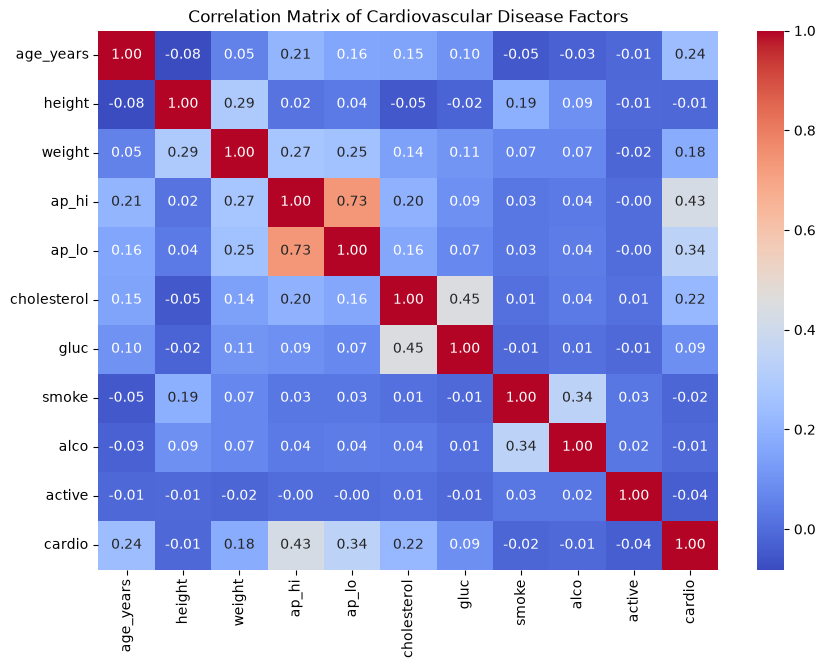

In [66]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Matrix of Cardiovascular Disease Factors")
plt.show()

In [67]:
cardio_counts = df_clean["cardio"].value_counts()

cardio_counts

cardio
0    34700
1    33974
Name: count, dtype: int64

In [68]:
cardio_pct = df_clean["cardio"].value_counts(normalize=True) * 100

cardio_pct

cardio
0    50.528584
1    49.471416
Name: proportion, dtype: float64

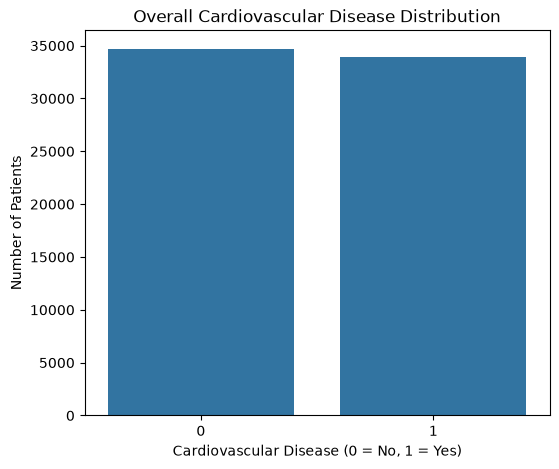

In [69]:
plt.figure(figsize=(6, 5))

sns.countplot(data=df_clean, x="cardio")

plt.title("Overall Cardiovascular Disease Distribution")
plt.xlabel("Cardiovascular Disease (0 = No, 1 = Yes)")
plt.ylabel("Number of Patients")

plt.show()

In [70]:
X = df_clean[
    [
        "age_years",
        "gender",
        "height",
        "weight",
        "ap_hi",
        "ap_lo",
        "cholesterol",
        "gluc",
        "smoke",
        "alco",
        "active"
    ]
]

y = df_clean["cardio"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (68674, 11)
Target shape: (68674,)


In [71]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (54939, 11)
Testing data: (13735, 11)


In [72]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling completed successfully.")

Scaling completed successfully.


In [73]:
import pandas as pd
import numpy as np

df = pd.read_csv("cardio_train.csv", sep=";")

df_clean = df.copy()

df_clean = df_clean[
    (df_clean["ap_hi"] >= 60) &
    (df_clean["ap_hi"] <= 250) &
    (df_clean["ap_lo"] >= 40) &
    (df_clean["ap_lo"] <= 200) &
    (df_clean["ap_hi"] >= df_clean["ap_lo"])
]

df_clean["age_years"] = (df_clean["age"] / 365.25).astype(int)

print(df_clean.shape)

(68674, 14)


In [74]:
X = df_clean[
    [
        "age_years",
        "gender",
        "height",
        "weight",
        "ap_hi",
        "ap_lo",
        "cholesterol",
        "gluc",
        "smoke",
        "alco",
        "active"
    ]
]

y = df_clean["cardio"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (68674, 11)
Target shape: (68674,)


In [75]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (54939, 11)
Testing data: (13735, 11)


In [76]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling completed successfully.")

Scaling completed successfully.


In [77]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

lr_model = LogisticRegression(max_iter=1000, random_state=42)

lr_model.fit(X_train_scaled, y_train)

y_pred_lr = lr_model.predict(X_test_scaled)

lr_accuracy = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:", lr_accuracy)
print("Logistic Regression Accuracy (%):", lr_accuracy * 100)

Logistic Regression Accuracy: 0.7262468147069531
Logistic Regression Accuracy (%): 72.62468147069531


In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_scaled, y_train)

y_pred_knn = knn_model.predict(X_test_scaled)

knn_accuracy = accuracy_score(y_test, y_pred_knn)

print("KNN Accuracy:", knn_accuracy)
print("KNN Accuracy (%):", knn_accuracy * 100)

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)

dt_accuracy = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", dt_accuracy)
print("Decision Tree Accuracy (%):", dt_accuracy * 100)

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", rf_accuracy)
print("Random Forest Accuracy (%):", rf_accuracy * 100)

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("cardio_train.csv", sep=";")

df_clean = df.copy()

df_clean = df_clean[
    (df_clean["ap_hi"] >= 60) &
    (df_clean["ap_hi"] <= 250) &
    (df_clean["ap_lo"] >= 40) &
    (df_clean["ap_lo"] <= 200) &
    (df_clean["ap_hi"] >= df_clean["ap_lo"])
]

df_clean["age_years"] = (df_clean["age"] / 365.25).astype(int)

print("Dataset restored:", df_clean.shape)

In [ ]:
X = df_clean[
    [
        "age_years", "gender", "height", "weight",
        "ap_hi", "ap_lo", "cholesterol", "gluc",
        "smoke", "alco", "active"
    ]
]

y = df_clean["cardio"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling completed successfully!")

In [ ]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score

svm_model = LinearSVC(
    random_state=42,
    max_iter=5000
)

svm_model.fit(X_train_scaled, y_train)

y_pred_svm = svm_model.predict(X_test_scaled)

svm_accuracy = accuracy_score(y_test, y_pred_svm)

print("SVM Accuracy:", round(svm_accuracy * 100, 2), "%")

In [ ]:

import pandas as pd

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "Decision Tree",
        "Random Forest",
        "SVM"
    ],
    "Accuracy (%)": [
        lr_accuracy * 100,
        knn_accuracy * 100,
        dt_accuracy * 100,
        rf_accuracy * 100,
        svm_accuracy * 100
    ]
})

results = results.sort_values(
    by="Accuracy (%)",
    ascending=False
).reset_index(drop=True)

results["Accuracy (%)"] = results["Accuracy (%)"].round(2)

results


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.barplot(
    data=results,
    x="Model",
    y="Accuracy (%)"
)

plt.title("Accuracy Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### Model Comparison and Findings

Five machine learning algorithms were evaluated on the same test dataset. Logistic Regression achieved the highest recorded accuracy of 72.62%, followed by SVM at 72.49%, Random Forest at 70.74%, KNN at 69.51%, and Decision Tree at 63.55%.

Based on accuracy, Logistic Regression performed best among the tested models. The confusion matrix and classification report were also used to evaluate its predictions.

These results apply to this dataset and test split. Further validation would be required before considering real-world use.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

df = pd.read_csv("cardio_train.csv", sep=";")

df_clean = df.copy()

df_clean = df_clean[
    (df_clean["ap_hi"] >= 60) &
    (df_clean["ap_hi"] <= 250) &
    (df_clean["ap_lo"] >= 40) &
    (df_clean["ap_lo"] <= 200) &
    (df_clean["ap_hi"] >= df_clean["ap_lo"])
].copy()

df_clean["age_years"] = (df_clean["age"] / 365.25).astype(int)

print("Dataset loaded:", df_clean.shape)

In [ ]:
features = [
    "age_years", "gender", "height", "weight",
    "ap_hi", "ap_lo", "cholesterol", "gluc",
    "smoke", "alco", "active"
]

X = df_clean[features]
y = df_clean["cardio"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling completed successfully!")

In [ ]:
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_scaled, y_train)

y_pred_lr = lr_model.predict(X_test_scaled)

lr_accuracy = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:",
      round(lr_accuracy * 100, 2), "%")

In [ ]:
cm = confusion_matrix(y_test, y_pred_lr)

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Disease", "Disease"]
)

cm_display.plot(cmap="Blues", values_format="d")

plt.title("Confusion Matrix - Logistic Regression")
plt.tight_layout()
plt.show()

In [ ]:
print("Classification Report:")
print(
    classification_report(
        y_test,
        y_pred_lr,
        target_names=["No Disease", "Disease"],
        digits=3
    )
)

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_lr)

print("Confusion Matrix:")
print(cm)

In [ ]:
import joblib

joblib.dump(lr_model, "logistic_regression_model.pkl")
joblib.dump(scaler, "scaler.pkl")

print("Model and scaler saved successfully!")

In [ ]:
loaded_model = joblib.load("logistic_regression_model.pkl")
loaded_scaler = joblib.load("scaler.pkl")

print("Saved model and scaler loaded successfully!")

In [ ]:
import pandas as pd

def predict_cardio(
    age_years,
    gender,
    height,
    weight,
    ap_hi,
    ap_lo,
    cholesterol,
    gluc,
    smoke,
    alco,
    active
):
    patient = pd.DataFrame([{
        "age_years": age_years,
        "gender": gender,
        "height": height,
        "weight": weight,
        "ap_hi": ap_hi,
        "ap_lo": ap_lo,
        "cholesterol": cholesterol,
        "gluc": gluc,
        "smoke": smoke,
        "alco": alco,
        "active": active
    }])

    patient_scaled = loaded_scaler.transform(patient)
    prediction = loaded_model.predict(patient_scaled)[0]

    if prediction == 1:
        return "Prediction: Cardiovascular disease detected by the model."
    else:
        return "Prediction: Cardiovascular disease not detected by the model."

In [ ]:
result = predict_cardio(
    age_years=55,
    gender=1,
    height=165,
    weight=75,
    ap_hi=140,
    ap_lo=90,
    cholesterol=2,
    gluc=1,
    smoke=0,
    alco=0,
    active=1
)

print(result)

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.barplot(
    data=results,
    x="Model",
    y="Accuracy (%)"
)

plt.title("Accuracy Comparison of ML Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## Conclusion

In this project, a machine learning approach was used to predict cardiovascular disease using patient health-related features. The dataset was cleaned by filtering implausible blood pressure records, and exploratory data analysis was performed to understand relationships between features and cardiovascular disease.

Five machine learning algorithms were evaluated: Logistic Regression, K-Nearest Neighbors (KNN), Decision Tree, Random Forest, and Support Vector Machine (SVM).

The recorded test accuracies were:

- Logistic Regression: 72.62%
- SVM: 72.49%
- Random Forest: 70.74%
- KNN: 69.51%
- Decision Tree: 63.55%

Among these experiments, Logistic Regression achieved the highest test accuracy of approximately 72.62%. A confusion matrix and classification report were also generated to evaluate its predictions beyond accuracy alone.

The trained Logistic Regression model and feature scaler were saved and used to create a prediction function for new input data.

**Limitation:** This project is for educational purposes only. Its predictions are not a medical diagnosis, and further validation and improvement would be required before any real-world clinical use.